1. Encabezado e importaciones principales

In [74]:
# AED
# Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Listar Archivos y cargar datos desde archivos

In [75]:
!dir

 Volume in drive C is Windows-SSD
 Volume Serial Number is 9CD6-4A19

 Directory of c:\Users\Roger\Videos\clon\PRACTICA_1-MODULO-3

11/06/2026  04:46 PM    <DIR>          .
11/04/2026  03:43 PM    <DIR>          ..
11/05/2026  10:48 PM         8,655,422 AED1_BERKA.ipynb
11/05/2026  10:48 PM            67,172 AED2_BERKA.ipynb
11/05/2026  10:48 PM    <DIR>          data
11/06/2026  05:20 PM           298,395 df_berka_unificado.csv
11/06/2026  04:46 PM    <DIR>          figuras_3_3
11/06/2026  04:46 PM           417,954 PREPARACION_BERKA.ipynb
11/05/2026  10:48 PM               326 requirements.txt
11/06/2026  04:46 PM            91,142 tabla_minable_berka.csv
               6 File(s)      9,530,411 bytes
               4 Dir(s)  49,498,144,768 bytes free


In [76]:
# Cargar archivos .asc del Banco Berka
df_client = pd.read_csv(r'C:\Users\Roger\Videos\Modulo 3\Caso Berka\data\client.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])
df_disp = pd.read_csv(r'C:\Users\Roger\Videos\Modulo 3\Caso Berka\data\disp.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])
df_account = pd.read_csv(r'C:\Users\Roger\Videos\Modulo 3\Caso Berka\data\account.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])
df_loan = pd.read_csv(r'C:\Users\Roger\Videos\Modulo 3\Caso Berka\data\loan.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

In [77]:
type(df_client)

pandas.core.frame.DataFrame

In [78]:
# Visualizamos las primeras filas del DataFrame df_
df_client.head()

,client_id,birth_number,district_id
0,1,706213,18
1,2,450204,1
2,3,406009,1
3,4,561201,5
4,5,605703,5


In [79]:
df_disp.head(8)

,disp_id,client_id,account_id,type
0,1,1,1,OWNER
1,2,2,2,OWNER
2,3,3,2,DISPONENT
3,4,4,3,OWNER
4,5,5,3,DISPONENT
5,6,6,4,OWNER
6,7,7,5,OWNER
7,8,8,6,OWNER


In [80]:
df_account.head()

,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


In [81]:
df_loan.head(10)

,loan_id,account_id,date,amount,duration,payments,status
0,5314,1787,930705,96396,12,8033.0,B
1,5316,1801,930711,165960,36,4610.0,A
2,6863,9188,930728,127080,60,2118.0,A
3,5325,1843,930803,105804,36,2939.0,A
4,7240,11013,930906,274740,60,4579.0,A
5,6687,8261,930913,87840,24,3660.0,A
6,7284,11265,930915,52788,12,4399.0,A
7,6111,5428,930924,174744,24,7281.0,B
8,7235,10973,931013,154416,48,3217.0,A
9,5997,4894,931104,117024,24,4876.0,A


In [82]:
# ¿Qué tipo datos contienen las columnas?

In [83]:
df_client.dtypes

client_id       int64
birth_number    int64
district_id     int64
dtype: object

In [84]:
df_disp.dtypes

disp_id        int64
client_id      int64
account_id     int64
type          object
dtype: object

In [85]:
df_account.dtypes

account_id      int64
district_id     int64
frequency      object
date            int64
dtype: object

In [86]:
df_loan.dtypes

loan_id         int64
account_id      int64
date            int64
amount          int64
duration        int64
payments      float64
status         object
dtype: object

In [87]:
# identificar el número de elementos de la base client
len(df_client)

5369

In [88]:
# identificar el número de elementos de la base disp
len(df_disp)

5369

In [89]:
# identificar el número de elementos de la base loan
len(df_loan)

682

In [90]:
# identificar el número de elementos de la base account
len(df_account)

4500

In [91]:
df_client.shape

(5369, 3)

3. Unificación de tablas, variable objetivo (Y) y casting

In [92]:
# Filtrar los titulares de la cuenta (type == OWNER)
df_disp_owner = df_disp[df_disp['type'] == 'OWNER']

In [93]:
len(df_disp_owner)

4500

In [94]:
# Unir client + disp (OWNER) + account
df_berka = pd.merge(df_client, df_disp_owner, on='client_id')
df_berka = pd.merge(df_berka, df_account, on='account_id', suffixes=('_client', '_account'))

In [95]:
# Unir con loan para obtener la información crediticia
df_berka = pd.merge(df_berka, df_loan[['account_id', 'amount', 'duration', 'payments', 'status']], on='account_id', how='left')

In [96]:
#Verificar la estructura del DataFrame resultante
df_berka.info()
df_berka.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   client_id            4500 non-null   int64  
 1   birth_number         4500 non-null   int64  
 2   district_id_client   4500 non-null   int64  
 3   disp_id              4500 non-null   int64  
 4   account_id           4500 non-null   int64  
 5   type                 4500 non-null   object 
 6   district_id_account  4500 non-null   int64  
 7   frequency            4500 non-null   object 
 8   date                 4500 non-null   int64  
 9   amount               682 non-null    float64
 10  duration             682 non-null    float64
 11  payments             682 non-null    float64
 12  status               682 non-null    object 
dtypes: float64(3), int64(7), object(3)
memory usage: 457.2+ KB


,client_id,birth_number,district_id_client,disp_id,account_id,type,district_id_account,frequency,date,amount,duration,payments,status
0,1,706213,18,1,1,OWNER,18,POPLATEK MESICNE,950324,NaN,NaN,NaN,NaN
1,2,450204,1,2,2,OWNER,1,POPLATEK MESICNE,930226,80952.0,24.0,3373.0,A
2,4,561201,5,4,3,OWNER,5,POPLATEK MESICNE,970707,NaN,NaN,NaN,NaN
3,6,190922,12,6,4,OWNER,12,POPLATEK MESICNE,960221,NaN,NaN,NaN,NaN
4,7,290125,15,7,5,OWNER,15,POPLATEK MESICNE,970530,NaN,NaN,NaN,NaN


In [97]:
#Vemos la forma del DataFrame resultante
df_berka.shape

(4500, 13)

In [98]:
### Creación de Variable Objetivo Y (Modelamiento Predictivo)
# 1: Buen cliente (status 'A' o 'C' en préstamo)
# 0: Mal cliente (status 'B' o 'D' en préstamo)
df_berka['target'] = df_berka['status'].map({'A': 1, 'C': 1, 'B': 0, 'D': 0})

In [99]:
df_berka['target'].value_counts()
df_berka['target'].value_counts(normalize=True)*100

target
1.0    88.856305
0.0    11.143695
Name: proportion, dtype: float64

In [100]:
# No importa que parezca número se debe convertir en object las variables identificadoras con asType()
df_berka = df_berka.astype({'client_id': 'object', 'district_id_client': 'object', 'account_id': 'object', 'district_id_account': 'object'})

In [101]:
df_berka.dtypes

client_id               object
birth_number             int64
district_id_client      object
disp_id                  int64
account_id              object
type                    object
district_id_account     object
frequency               object
date                     int64
amount                 float64
duration               float64
payments               float64
status                  object
target                 float64
dtype: object

In [102]:

df_berka.describe(include='all')

,client_id,birth_number,district_id_client,disp_id,account_id,type,district_id_account,frequency,date,amount,duration,payments,status,target
count,4500.0,4500.000000,4500.0,4500.000000,4500.0,4500,4500.0,4500,4500.000000,682.000000,682.000000,682.000000,682,682.000000
unique,4500.0,NaN,77.0,NaN,4500.0,1,77.0,3,NaN,NaN,NaN,NaN,4,NaN
top,1.0,NaN,1.0,NaN,1.0,OWNER,1.0,POPLATEK MESICNE,NaN,NaN,NaN,NaN,C,NaN
freq,1.0,NaN,547.0,NaN,1.0,4500,554.0,4167,NaN,NaN,NaN,NaN,403,NaN
mean,NaN,541971.717333,NaN,3359.468000,NaN,NaN,NaN,NaN,951654.608667,151410.175953,36.492669,4190.664223,NaN,0.888563
std,NaN,171012.436816,NaN,2777.876453,NaN,NaN,NaN,NaN,14842.188377,113372.406310,17.075219,2215.830344,NaN,0.314903
min,NaN,180107.000000,NaN,1.000000,NaN,NaN,NaN,NaN,930101.000000,4980.000000,12.000000,304.000000,NaN,0.000000
25%,NaN,415620.250000,NaN,1424.750000,NaN,NaN,NaN,NaN,931227.000000,66732.000000,24.000000,2477.000000,NaN,1.000000
50%,NaN,550419.500000,NaN,2861.000000,NaN,NaN,NaN,NaN,960102.000000,116928.000000,36.000000,3934.000000,NaN,1.000000
75%,NaN,690246.500000,NaN,4287.250000,NaN,NaN,NaN,NaN,961101.000000,210654.000000,48.000000,5813.500000,NaN,1.000000


4. Agrupaciones y gráficos de variables cualitativas

In [103]:
### Agrupaciones
# “POPLATEK MESICNE” (emisión mensual): el extracto llega una vez al mes.
# “POPLATEK TYDNE” (emisión semanal): el extracto llega una vez por semana.
# “POPLATEK PO OBRATU” (emisión tras cada transacción): el extracto se genera cada vez que hay
df_berka.groupby('frequency').size()

frequency
POPLATEK MESICNE      4167
POPLATEK PO OBRATU      93
POPLATEK TYDNE         240
dtype: int64

In [104]:
frequency_agrupado = df_berka.groupby('frequency').size()
frequency_agrupado

frequency
POPLATEK MESICNE      4167
POPLATEK PO OBRATU      93
POPLATEK TYDNE         240
dtype: int64

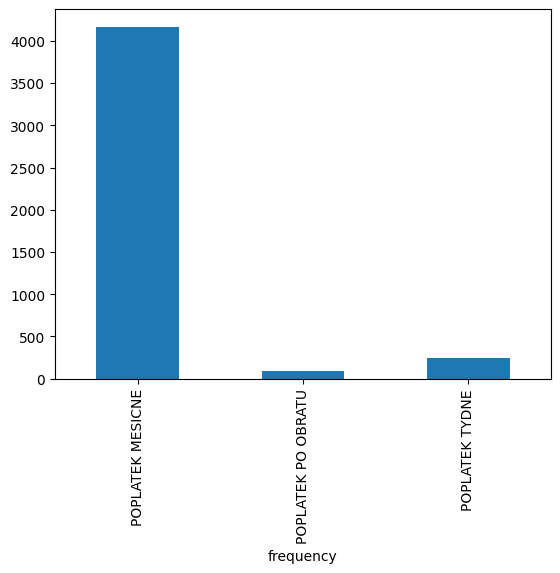

In [105]:
frequency_agrupado.plot.bar('frequency')
plt.show()

In [106]:
# Otra manera de representar en porcentaje
df_berka['frequency'].value_counts(normalize=True)*100

frequency
POPLATEK MESICNE      92.600000
POPLATEK TYDNE         5.333333
POPLATEK PO OBRATU     2.066667
Name: proportion, dtype: float64


6. Análisis de variables cuantitativas (Estadísticos centrales y dispersión)

## Grafica variable cuantitativa
# Se utiliza graficos de histogramas

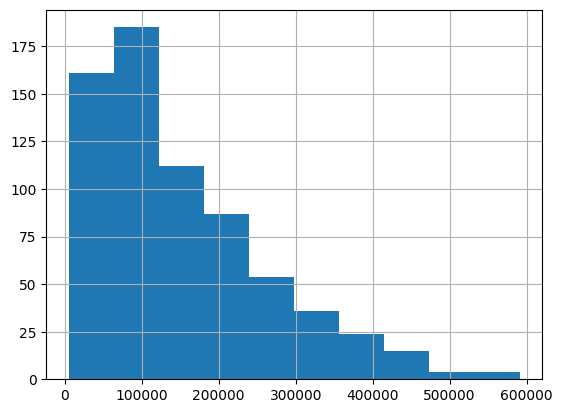

In [107]:
df_berka['amount'].hist(bins=10)
plt.show()

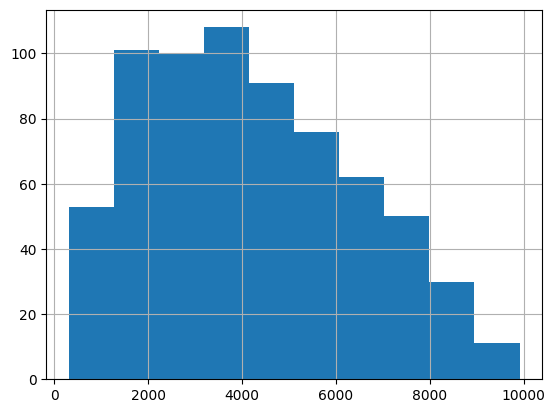

In [108]:
df_berka['payments'].hist(bins=10)
plt.show()

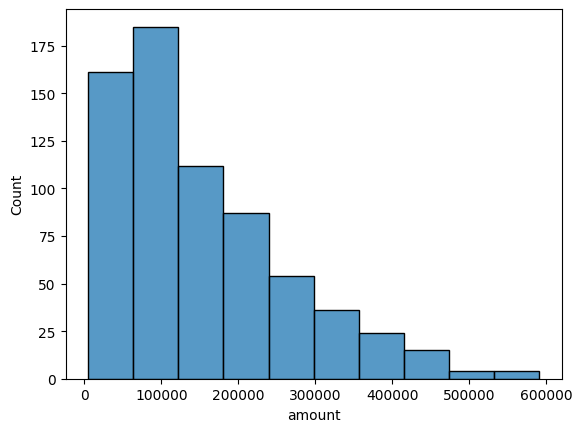

In [109]:
# graficando con seaborn
sns.histplot(data=df_berka, x='amount', bins=10)
plt.show()

# **Media**
# Cual es la media de las variable cuantitativas de la variable df_berka.amount, df_berka.payments

In [110]:
df_berka['amount'].mean()

np.float64(151410.1759530792)

In [111]:
df_berka['payments'].mean()

np.float64(4190.6642228739)

# **Mediana**
# Cual es la mediana de las variable cuantitativas de la variable df_berka.amount, df_berka.payments

In [112]:
df_berka['amount'].median()

np.float64(116928.0)

In [113]:
df_berka['payments'].median()

np.float64(3934.0)

# **Moda**
# Cual es la moda de las variable cuantitativas de la variable df_berka.amount, df_berka.payments

In [114]:
df_berka['amount'].mode()
df_berka['payments'].mode()

0    2523.0
1    3151.0
Name: payments, dtype: float64

6. Medidas de dispersión

In [115]:
# Rango
maximo = df_berka['amount'].max()
minimo = df_berka['amount'].min()
rango = maximo - minimo

In [116]:
maximo

np.float64(590820.0)

In [117]:
minimo

np.float64(4980.0)

In [118]:
rango

np.float64(585840.0)

In [119]:
# Cuartiles
q1, q3 = np.percentile(df_berka['amount'].dropna(), [25,75])

In [120]:
q1

np.float64(66732.0)

In [121]:
q3

np.float64(210654.0)

In [122]:
# Rango intercuartil
RIC = q3 - q1
RIC

np.float64(143922.0)

In [123]:
# Varianza
df_berka['amount'].var()

np.float64(12853302512.427147)

In [124]:
# Desviacion Estandar
df_berka['amount'].std()

np.float64(113372.4063095917)

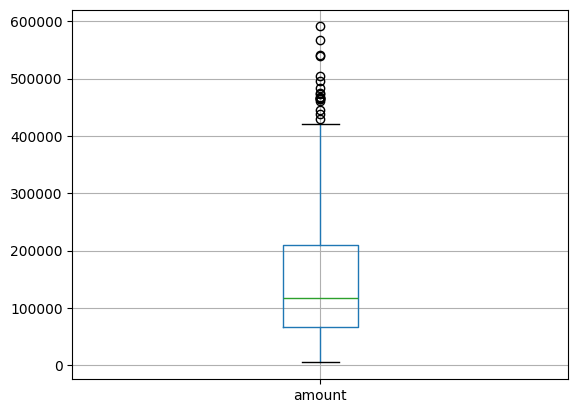

In [125]:
# Grafico Box plot
df_berka.boxplot('amount')
plt.show()

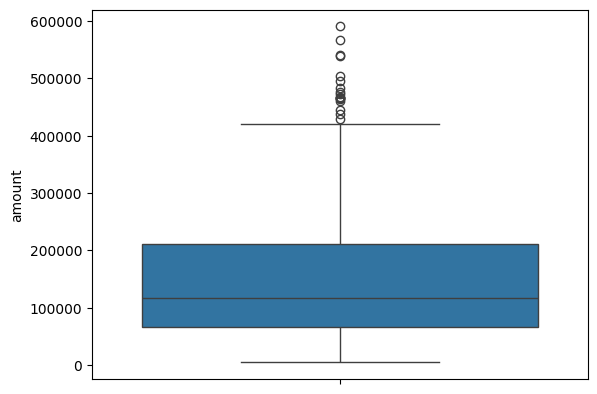

In [126]:
sns.boxplot(data=df_berka['amount'])
plt.show()

In [127]:
df_berka.head(2).T

,0,1
client_id,1,2
birth_number,706213,450204
district_id_client,18,1
disp_id,1,2
account_id,1,2
type,OWNER,OWNER
district_id_account,18,1
frequency,POPLATEK MESICNE,POPLATEK MESICNE
date,950324,930226
amount,NaN,80952.0


7. AED entre varias variables y Data Profiling

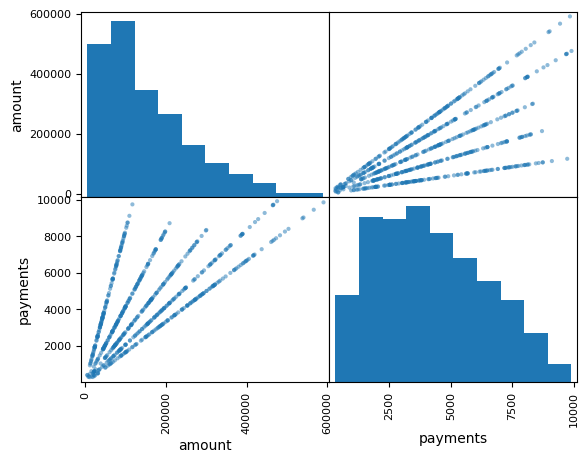

In [128]:
pd.plotting.scatter_matrix(df_berka[['amount','payments']], alpha=0.5)
plt.show()

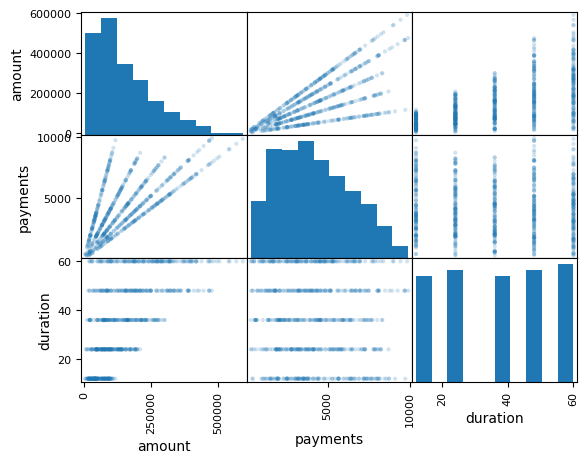

In [129]:
pd.plotting.scatter_matrix(df_berka[['amount','payments', 'duration']], alpha=0.2)
plt.show()

<Axes: xlabel='amount', ylabel='payments'>

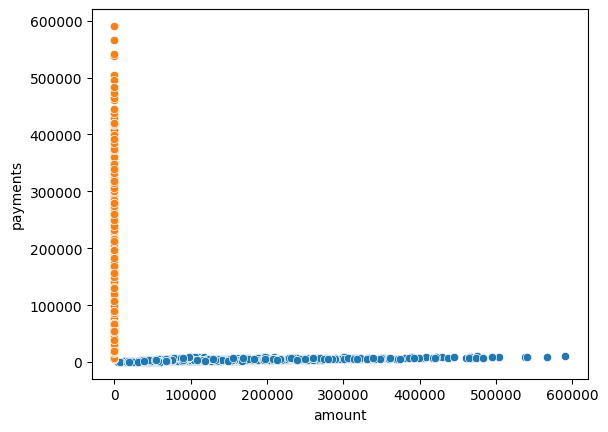

In [130]:
sns.scatterplot(data=df_berka, x='amount', y='payments')
sns.scatterplot(data=df_berka, x='duration', y='amount')

In [131]:
corr_df = df_berka[['amount', 'payments']].corr(method='pearson')

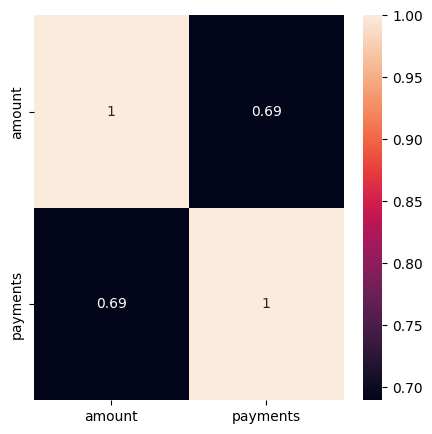

In [132]:
plt.figure(figsize=(5, 5))
sns.heatmap(corr_df, annot=True)
plt.show()

In [133]:
corr_df = df_berka[['amount', 'payments', 'duration', 'target']].corr(method='pearson')

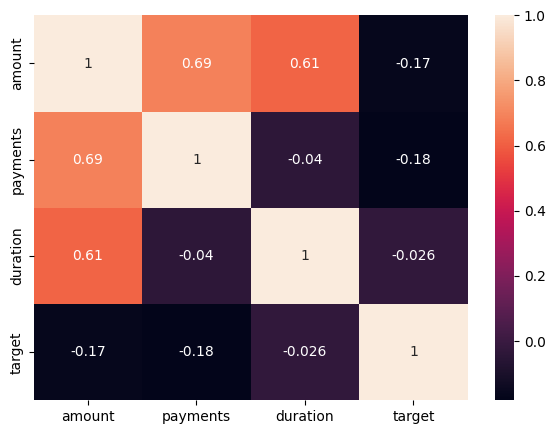

In [134]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr_df, annot=True)
plt.show()

 Data Profiling

In [135]:
%pip install ydata-profiling ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [136]:
import numpy as np
import pandas as pd
from ydata_profiling import ProfileReport

In [137]:
profile = ProfileReport(df_berka, title="Profiling Report Banco Berka")
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 14/14 [00:00<00:00, 938.16it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [138]:
df_berka.to_csv('df_berka_unificado.csv', index=False)

In [68]:
# 1. Lista completa de las 14 variables de df_berka
cols_cuantitativas = ['amount', 'payments', 'duration']
cols_cualitativas = [
    'client_id',
    'account_id',
    'disp_id',
    'district_id_client',
    'district_id_account',
    'type',
    'frequency',
    'status',
    'birth_number',
    'date',
    'target',
]

In [69]:
# 2. Función para Estadísticos Cuantitativos (Tendencia Central y Dispersión)
def stats_cuantitativas(df, columnas):
    resultados = []
    for col in columnas:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        resultados.append({
            'Variable': col,
            'Registros (n)': int(s.count()),
            'Media': round(s.mean(), 2),
            'Mediana': round(s.median(), 2),
            'Moda': round(s.mode()[0], 2) if not s.mode().empty else np.nan,
            'Desv. Estándar': round(s.std(), 2),
            'Varianza': round(s.var(), 2),
            'Mínimo': round(s.min(), 2),
            'Máximo': round(s.max(), 2),
            'Rango': round(s.max() - s.min(), 2),
            'Q1 (25%)': round(q1, 2),
            'Q3 (75%)': round(q3, 2),
            'RIC (IQR)': round(q3 - q1, 2),
        })
    return pd.DataFrame(resultados).set_index('Variable').T

In [70]:
# 3. Función para Estadísticos Cualitativos e Identificadores (Frecuencias y Categorías)
def stats_cualitativas(df, columnas):
    resultados = []
    for col in columnas:
        s = df[col]
        s_valid = s.dropna()
        top_val = s_valid.mode()[0] if not s_valid.empty else np.nan
        top_freq = (
            (s_valid == top_val).sum() if pd.notna(top_val) else 0
        )
        top_pct = (
            round((top_freq / len(s_valid)) * 100, 2)
            if len(s_valid) > 0
            else 0
        )

        resultados.append({
            'Variable': col,
            'Registros Válidos': int(s_valid.count()),
            'Nulos (Missing)': int(s.isna().sum()),
            'Valores Únicos': int(s_valid.nunique()),
            'Valor / Categoría Top': str(top_val),
            'Frecuencia Top': int(top_freq),
            '% Frecuencia Top': f'{top_pct}%',
        })
    return pd.DataFrame(resultados).set_index('Variable').T

In [71]:
# 4. Generar las dos tablas
tabla_cuantitativas = stats_cuantitativas(df_berka, cols_cuantitativas)
tabla_cualitativas = stats_cualitativas(df_berka, cols_cualitativas)

In [72]:
print('=== 1. ESTADÍSTICAS CUANTITATIVAS (Monto, Cuota, Plazo) ===')
print(tabla_cuantitativas)

=== 1. ESTADÍSTICAS CUANTITATIVAS (Monto, Cuota, Plazo) ===
Variable              amount    payments  duration
Registros (n)   6.820000e+02      682.00    682.00
Media           1.514102e+05     4190.66     36.49
Mediana         1.169280e+05     3934.00     36.00
Moda            3.027600e+04     2523.00     60.00
Desv. Estándar  1.133724e+05     2215.83     17.08
Varianza        1.285330e+10  4909904.11    291.56
Mínimo          4.980000e+03      304.00     12.00
Máximo          5.908200e+05     9910.00     60.00
Rango           5.858400e+05     9606.00     48.00
Q1 (25%)        6.673200e+04     2477.00     24.00
Q3 (75%)        2.106540e+05     5813.50     48.00
RIC (IQR)       1.439220e+05     3336.50     24.00


In [73]:
print(
    '\n=== 2. ESTADÍSTICAS CUALITATIVAS E IDENTIFICADORES (11 Variables) ==='
)
print(tabla_cualitativas)


=== 2. ESTADÍSTICAS CUALITATIVAS E IDENTIFICADORES (11 Variables) ===
Variable              client_id account_id disp_id district_id_client  \
Registros Válidos          4500       4500    4500               4500   
Nulos (Missing)               0          0       0                  0   
Valores Únicos             4500       4500    4500                 77   
Valor / Categoría Top         1          1       1                  1   
Frecuencia Top                1          1       1                547   
% Frecuencia Top          0.02%      0.02%   0.02%             12.16%   

Variable              district_id_account    type         frequency  status  \
Registros Válidos                    4500    4500              4500     682   
Nulos (Missing)                         0       0                 0    3818   
Valores Únicos                         77       1                 3       4   
Valor / Categoría Top                   1   OWNER  POPLATEK MESICNE       C   
Frecuencia Top        